In [1]:
%matplotlib widget
import importlib
import numpy as np
import os
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import pandas as pd
import io
import elli

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Permittivity_study\fit_interband_permittivity')
from fit_interband_func import *
import fit_interband_func
importlib.reload(fit_interband_func)
from fit_interband_func  import *


fontsize=30
import matplotlib as mpl
mpl.rcParams["font.size"] = 18

In [2]:
Ag_band_info = {}

## From the mathematica code used for Stoll 2014

Source = 'Rosei 1974' #As it is named in the mathematica code

if Source == 'Rosei 1974' :
    # Masses in electron mass unit    
    Ag_band_info['m_d_perp'] = 2.075
    Ag_band_info['m_d_par'] = 2.580

    Ag_band_info['m_p_perp'] = 0.320
    Ag_band_info['m_p_par'] = 0.172 
        
    Ag_band_info['m_s_perp'] = 5.160
    Ag_band_info['m_s_par'] = 0.128


    #Optical gaps in eV from Rosei
    Ag_band_info['wf'] = 310e-3 #in eV
    Ag_band_info['wo'] = 3680e-3 #in eV
    Ag_band_info['wg'] = 3850e-3 #in eV

    # Fermi Energy from Ascroft solid state physics
    Ag_band_info['Ef'] = 5.490 #in eV

    #Drude parameters
    Ag_band_info['hbar_wp'] = 8.98 #in eV
    Ag_band_info['hbar_gamma0'] = 0.02 #in eV


Ef = Ag_band_info['Ef'] #in eV
Emin = Ef - 5

m_p_perp = Ag_band_info['m_p_perp']
m_p_par = Ag_band_info['m_p_par']
m_d_perp = Ag_band_info['m_d_perp']
m_d_par = Ag_band_info['m_d_par']

#gaps in eV
wf = Ag_band_info['wf'] 
wo = Ag_band_info['wo']




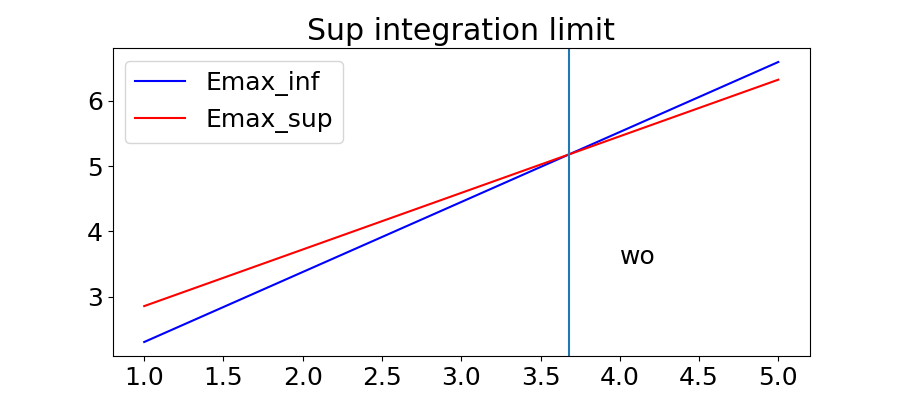

In [3]:
W = np.linspace(1, 5, 1000)

Emax_inf = (Ef - wf + (m_d_par/(m_d_par - m_p_par))*(W-wo))
Emax_sup = (Ef - wf + (m_d_perp/(m_d_perp + m_p_perp))*(W-wo))


fig, ax =plt.subplots(figsize=(9,4))
ax.plot(W, Emax_inf, color='blue', label='Emax_inf')
ax.plot(W, Emax_sup, color='red', label='Emax_sup')
ax.axvline(wo)
ax.text(4, 3.5, 'wo')
ax.set_title('Sup integration limit')
ax.legend()



6.323632567849687 6.594285714285714 6.323632567849687
6.323632567849687


Text(0.5, 1.0, 'Ddp')

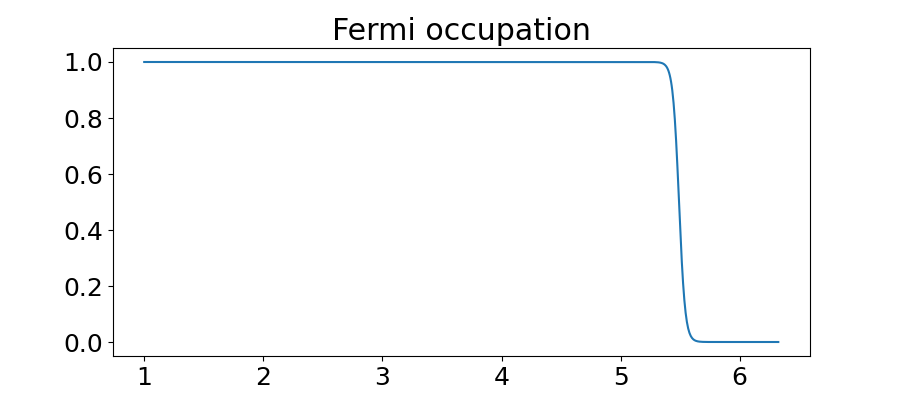

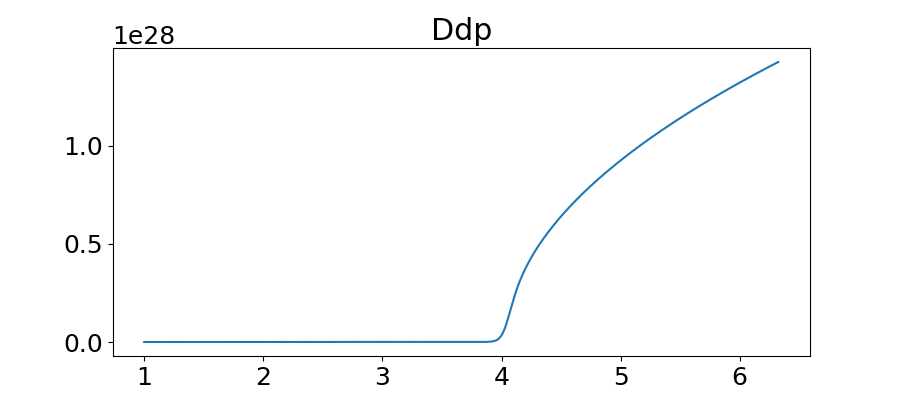

In [4]:
w = 5
    
Emax = (w < wo) * (Ef - wf + (m_d_par/(m_d_par - m_p_par))*(w-wo)) + (w >= wo) * (Ef - wf + (m_d_perp/(m_d_perp + m_p_perp))*(w-wo))



print(Emax, (Ef - wf + (m_d_par/(m_d_par - m_p_par))*(w-wo)), (Ef - wf + (m_d_perp/(m_d_perp + m_p_perp))*(w-wo)))

#squareroot becomes negative
Elim = Ef + 1/(m_d_perp + m_p_perp)*(-m_p_perp*wf + m_d_perp*(w-wo-wf)) 
print(Elim)

E = np.linspace(1, Emax, 1000) #in eV

fig, ax =plt.subplots(figsize=(9,4))
ax.plot(E, fermi_dist(E, Ag_band_info['Ef'], 300))
ax.set_title('Fermi occupation')


fig, ax =plt.subplots(figsize=(9,4))
X = E
Y = Jdp_Ag(E, **Ag_band_info)
ax.plot(X, Y)
ax.set_title('Ddp')
#print([(Y[i], E[i]) for i in range(len(Y))])

## Problème : pour w>w0, Emax est exactement la valeur du pôle de D et donc l'intégration fonctionne mal...

In [5]:
E = np.linspace(1, 6, 100) #in eV
prefactor = 8*np.pi**2 * sc.constants.e**2 * sc.constants.hbar**2 / (sc.constants.epsilon_0*sc.constants.m_e**2)
Jdp = Jdp_Ag(E, Ag_band_info)
Jdp2 = Jdp_Ag_v2(E, Ag_band_info)



fig, ax =plt.subplots(figsize=(9,4))

ax.plot(E, Jdp, color='blue')
ax.plot(E, Jdp2, color='green')


#print(Jdp)

fig, ax =plt.subplots(figsize=(9,4))
ax.plot(E, prefactor*Jdp/E**2)
ax.set_title('Jdp')

KeyError: 'Ef'

In [ ]:

print(prefactor)

3.067864124761743e-33
